# Getting started with spectrapy

spectrapy turns spectra (power versus wavelength) into colours and draws spectral pictures with
matplotlib. This notebook is a guided tour; every figure function returns an `Axes` or a `Figure`
that you can keep editing.

```bash
pip install "git+https://github.com/fdragowski480677/spectrapy.git"
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import spectrapy as sp

sp.style.use("light")                   # or "dark"; plain matplotlib styles work too
plt.rcParams["figure.dpi"] = 90         # keep the notebook light
sp.__version__

'0.3.0'

## 1. Spectra and their colours

A `Spectrum` is a wavelength grid (nm) plus values. Light sources are `kind="emission"`; for
those, `sp.xyz` integrates against the CIE colour-matching functions and `Y` comes out as luminance.

In [2]:
sun = sp.blackbody(5772)                # the Sun as a 5772 K blackbody
print(sun)
print("XYZ:", sp.xyz(sun))
print("colour:", sp.hex_color(sun))
T, duv = sp.cct(sp.xyz(sun))
print(f"CCT = {float(T):.0f} K, Duv = {float(duv):+.4f}")

Spectrum('Blackbody 5772 K', emission, 360-830 nm, 471 samples)
XYZ: [1.79276312e+09 1.84371426e+09 1.85348054e+09]
colour: #fff1ea
CCT = 5772 K, Duv = -0.0000


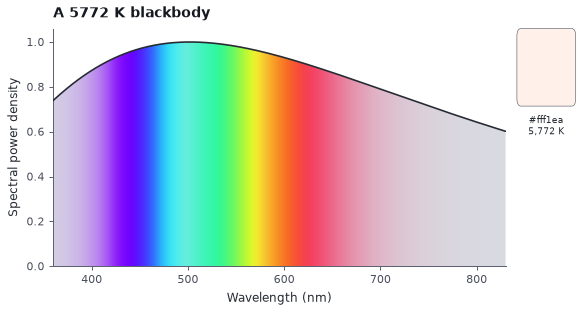

In [3]:
ax = sp.plot.spectrum(sun.normalize("max"))
ax.set_title("A 5772 K blackbody");

Arrays of temperatures give *batches* of spectra, and everything is vectorized:

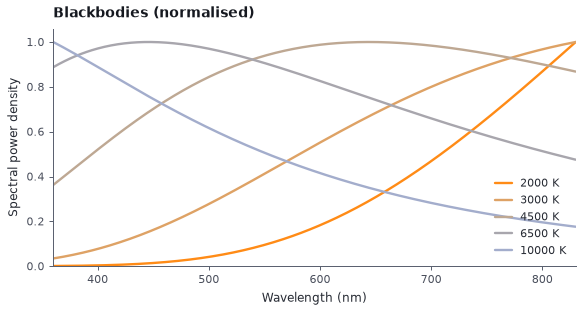

In [4]:
T = np.array([2000, 3000, 4500, 6500, 10000])
batch = sp.blackbody(T, normalize="max")
ax = sp.plot.spectrum(batch, label=[f"{t} K" for t in T])   # lines in each spectrum's own colour
ax.set_title("Blackbodies (normalised)");

In [5]:
%%time
colors = sp.color(sp.blackbody(np.linspace(1000, 20000, 10_000)))   # 10 000 spectra -> sRGB
colors.shape

(10000, 3)

## 2. CIE illuminants and the chromaticity diagram

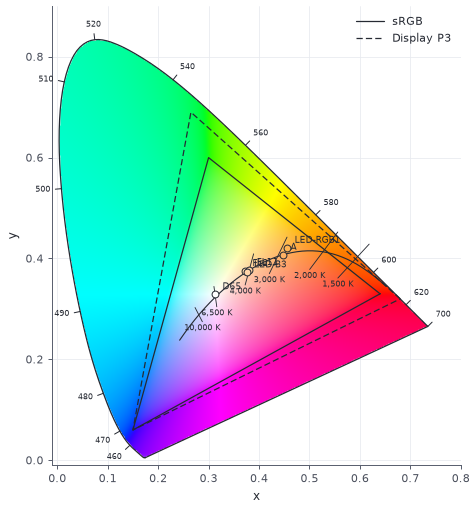

In [6]:
names = ["A", "D65", "FL2", "FL11", "LED-B3", "LED-RGB1"]
ax = sp.plot.chromaticity_diagram(gamuts=("sRGB", "Display P3"), resolution=400)
for n in names:
    sp.plot.chromaticity_points(ax, sp.illuminant(n), [n])

## 3. Line spectra and the spectroscope view

Discrete lines are exact delta functions for colour calculations; they are only broadened for
drawing.

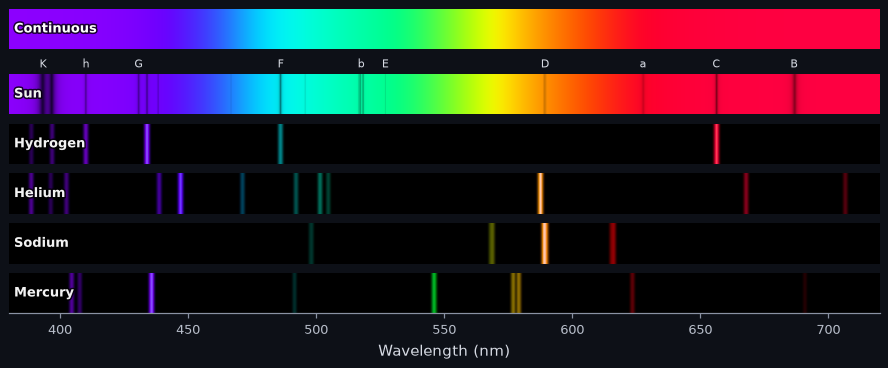

In [7]:
with sp.style.context("dark"):
    fig = sp.plot.emission_atlas(("H", "He", "Na", "Hg"))
plt.show()

## 4. Your own measured spectra

`sp.io.read_spectrum` (or `parse_spectrum` for strings) reads two-column text in nm, Å, µm, eV,
cm⁻¹ or THz. Densities per energy unit are converted with the Jacobian, so colours stay right.

Spectrum('green LED', emission, 413.281-652.548 nm, 300 samples) peak at 531.2 nm


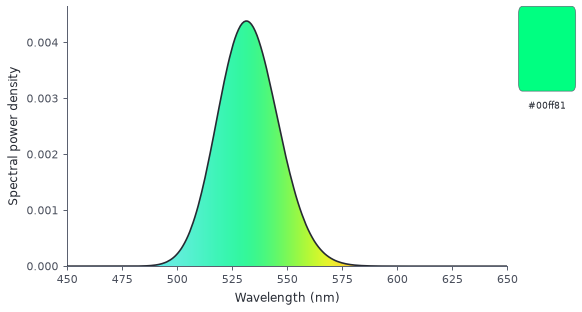

In [8]:
energies = np.linspace(1.9, 3.0, 300)                    # photon energy, eV
led = np.exp(-0.5 * ((energies - 2.33) / 0.06) ** 2)      # a green LED, per eV
text = "\n".join(f"{e:.4f}, {v:.6f}" for e, v in zip(energies, led))
measured = sp.io.parse_spectrum(text, unit="eV", name="green LED")
print(measured, "peak at", round(float(measured.peak_wavelength), 1), "nm")
sp.plot.spectrum(measured, xlim=(450, 650));

## 5. Thin-film interference

Multilayers are computed with the transfer-matrix method, vectorized over wavelength, angle and
thickness.

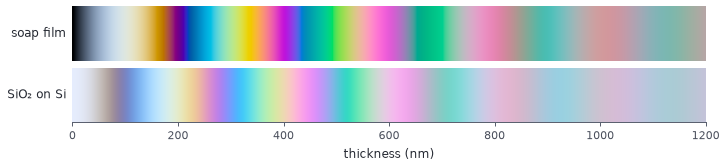

In [9]:
tf = sp.thinfilm
d = np.linspace(0, 1200, 600)
soap = tf.Stack([(tf.WATER, 0)], ambient=tf.AIR, substrate=tf.AIR)
oxide = tf.Stack([(tf.SIO2, 0)], ambient=tf.AIR, substrate=tf.SI)
fig, axes = plt.subplots(2, 1, figsize=(8, 1.8), sharex=True)
sp.plot.color_strip(d, sp.color(soap.scan(0, d), brightness="global"), ax=axes[0], ticks=False,
                    label="soap film")
sp.plot.color_strip(d, sp.color(oxide.scan(0, d), brightness="global"), ax=axes[1], label="SiO₂ on Si")
axes[1].set_xlabel("thickness (nm)");

## 6. Colour rendering: CRI and TM-30

CRIResult(Ra=80.3, R9=7.0, CCT=6591 K, Duv=+0.0009)
TM30Result(Rf=79.5, Rg=94.1, CCT=6598 K, Duv=+0.0009)


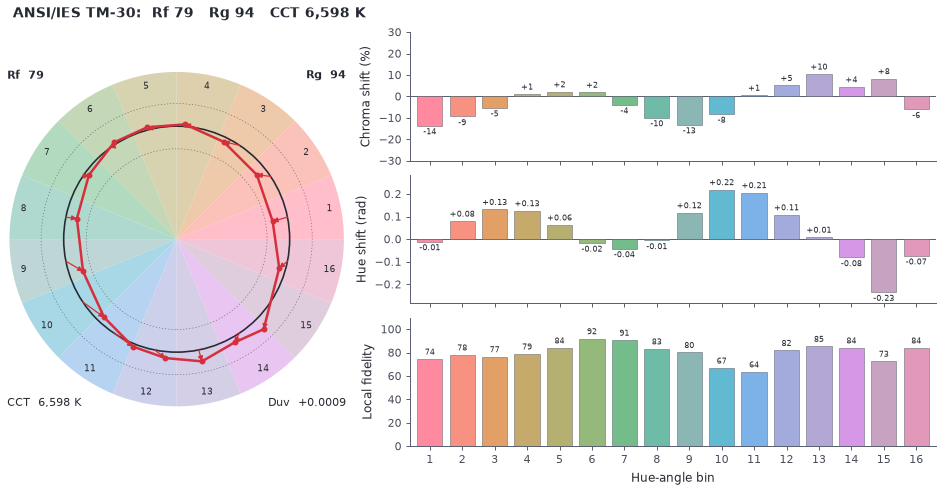

In [10]:
led = sp.illuminant("LED-B5")
print(sp.cri(led))
print(sp.tm30(led))
fig = sp.plot.tm30_report(sp.tm30(led))

## 7. Wide-gamut figures

Spectral colours are far more saturated than sRGB allows. Render in Display P3 and save; the PNG
carries an ICC profile, so colour-managed viewers (browsers, macOS, iOS, Windows) show the
extra saturation:

```python
with sp.output_space("p3"):
    fig = sp.plot.emission_atlas()
    sp.style.save(fig, "atlas_p3.png")
```

## Where next

* The [gallery](https://github.com/fdragowski480677/spectrapy#gallery) shows what else is in
  the box: rainbows, prisms, gratings, sky colours, star colours, AR coatings and more. Each figure
  is a short recipe in `src/spectrapy/gallery.py`.
* [`docs/API.md`](https://github.com/fdragowski480677/spectrapy/blob/main/docs/API.md) is the full
  API reference.
* `sp.interactive.blackbody_explorer()` and `sp.interactive.thinfilm_explorer()` give slider-driven
  explorers (they need an interactive matplotlib backend).